In [1]:
import pandas as pd

In [2]:
import numpy as np 

In [3]:
import matplotlib.pyplot as plt

In [4]:
import yfinance as yf

In [5]:
import mplfinance as mpf

# VALUATION EXERCISE: FERRARI vs PORSCHE 

In [6]:
Market_Input = pd.DataFrame({
    'Inputs':['Closing Price-USD', 'Exchange rate-USD per EUR', 'Issued common shares','Treasury common shares'],
    'Value':[389.91, 1.1206, 177278893, 1878927],
    'Date': ['2026-10-09', '2026-10-09', '2026-07-24','2026-10-02']
})

In [7]:
pd.options.display.float_format = "{:,.4f}".format

In [8]:
Market_Input

,Inputs,Value,Date
0,Closing Price-USD,389.9100,2026-10-09
1,Exchange rate-USD per EUR,1.1206,2026-10-09
2,Issued common shares,"177,278,893.0000",2026-07-24
3,Treasury common shares,"1,878,927.0000",2026-10-02


In [9]:
Shares_Outstanding = (Market_Input.loc[2, 'Value'] - Market_Input.loc[3, 'Value'])

In [10]:
Price_EUR = Market_Input.loc[0, 'Value']/Market_Input.loc[1, 'Value']

In [11]:
Market_Capitalization = Price_EUR * Shares_Outstanding 

In [12]:
print (Market_Capitalization)

61029984600.267715


In [13]:
Balance_Input = pd.DataFrame({
        'Input': ['Total Debt', 'Cash and Cash Equivalent', 'Non-Controlling Asset'],
        'Value(Million)': [3165.647, 1485.762, 6.237]
})

In [14]:
Balance_Input

,Input,Value(Million)
0,Total Debt,"3,165.6470"
1,Cash and Cash Equivalent,"1,485.7620"
2,Non-Controlling Asset,6.2370


In [15]:
Balance_Input['Converted']= Balance_Input['Value(Million)']*1000000

In [16]:
Balance_Input

,Input,Value(Million),Converted
0,Total Debt,"3,165.6470","3,165,647,000.0000"
1,Cash and Cash Equivalent,"1,485.7620","1,485,762,000.0000"
2,Non-Controlling Asset,6.2370,"6,237,000.0000"


In [17]:
Net_Debt = (Balance_Input.loc[0, 'Converted']-Balance_Input.loc[1, 'Converted']+Balance_Input.loc[2, 'Converted'])

In [18]:
ENTERPRISE_VALUE = Market_Capitalization + Net_Debt 

In [19]:
Earnings_Inputs = pd.DataFrame({
        'METRIC':['EBITDA','NET PROFIT'],
        'FY2025':[2772, 1597],
        'H12025':[1402, 835.909],
        'H12026':[1477, 875.106]
})

In [20]:
Earnings_Inputs

,METRIC,FY2025,H12025,H12026
0,EBITDA,2772,"1,402.0000","1,477.0000"
1,NET PROFIT,1597,835.9090,875.1060


In [21]:
TTM_EBITDA = (Earnings_Inputs.loc[0, 'FY2025']-Earnings_Inputs.loc[0, 'H12025'] + Earnings_Inputs.loc[0, 'H12026'])

In [22]:
TTM_NET_PROFIT = (Earnings_Inputs.loc[1, 'FY2025']-Earnings_Inputs.loc[1, 'H12025'] + Earnings_Inputs.loc[1, 'H12026'])

Note: TTM means Trailing Twelve Month (FY2025 - H12025 + H12026)

In [23]:
print (TTM_EBITDA)
print (TTM_NET_PROFIT)

2847.0
1636.1970000000001


In [24]:
TTM_EBITDA

np.float64(2847.0)

In [25]:
TTM_EBITDA = TTM_EBITDA*1000000

In [26]:
EV_EBITDA = ENTERPRISE_VALUE / TTM_EBITDA

In [27]:
EV_EBITDA

np.float64(22.02883969099674)

EV_EBITDA of 22x suggest that the enterprise value of ferrari represents 22x its TTM EBITDA

In [28]:
TTM_NET_PROFIT = TTM_NET_PROFIT*1000000

In [29]:
EPS = TTM_NET_PROFIT / Shares_Outstanding

In [30]:
EPS

np.float64(9.328376950768622)

EPS is 9.33EUR - this is the part of the company profit attributed to every ordinary share

In [31]:
PE_Ratio = Price_EUR / EPS

In [32]:
PE_Ratio

np.float64(37.299900073321076)

P/E ratio of 37.2x means investors are paying 37.2EUR for every 1EUR of Ferrari's TTM Earnings 

In [33]:
Ferrari_Valuation = pd.DataFrame({
    'Metric':[
        'Share Price', 'Estimated Share Outstanding',
        'Market Capitalization', 'Enterprise Value',
        'TTM EBITDA', 'TTM Net Profit', 'TTM EPS',
        'P/E', 'EV/EBITDA'],
    'Value':[Price_EUR, Shares_Outstanding/1_000_000, Market_Capitalization/1_000_000,
            ENTERPRISE_VALUE/1_000_000, TTM_EBITDA/1_000_000, TTM_NET_PROFIT/1_000_000, EPS,
            PE_Ratio, EV_EBITDA],
    'Unit': ['€ per share', 'Million shares', '€ million',
        '€ million', '€ million', '€ million',
        '€ per share', '×', '×']
        })
Ferrari_Valuation.style.format({'Value': '{:,.2f}'}).hide(axis='index')

Metric,Value,Unit
Share Price,347.95,€ per share
Estimated Share Outstanding,175.40,Million shares
Market Capitalization,"61,029.98",€ million
Enterprise Value,"62,716.11",€ million
TTM EBITDA,"2,847.00",€ million
TTM Net Profit,"1,636.20",€ million
TTM EPS,9.33,€ per share
P/E,37.30,×
EV/EBITDA,22.03,×


In [34]:
Porsche_Market_Input = pd.DataFrame({
    'Inputs':['Preferred share closing Price(€)', 'Ordinary shares', 'Preferred shares'],
    'Value':[41.54, 455500000, 455500000],
    'Date': ['2026-10-09', '2026-06-30', '2026-06-30']
})

In [35]:
Porsche_Market_Input

,Inputs,Value,Date
0,Preferred share closing Price(€),41.5400,2026-10-09
1,Ordinary shares,"455,500,000.0000",2026-06-30
2,Preferred shares,"455,500,000.0000",2026-06-30


In [36]:
Total_Shares = Porsche_Market_Input['Value'].iloc[1] + Porsche_Market_Input['Value'].iloc[2]

In [37]:
Total_Shares

np.float64(911000000.0)

In [38]:
Porsche_Market_Cap = Total_Shares * Porsche_Market_Input['Value'].iloc[0]

In [39]:
Porsche_Balance_Input = pd.DataFrame({
        'Input': ['Non-Current Financial Liabilities', 'Current Financial Liabilities',
                  'Cash and Cash Equivalent', 'Non-Controlling interest'],
        'Value(€ Million)': [6734, 5078, 4559, 85]
})

In [40]:
Porsche_Balance_Input

,Input,Value(€ Million)
0,Non-Current Financial Liabilities,6734
1,Current Financial Liabilities,5078
2,Cash and Cash Equivalent,4559
3,Non-Controlling interest,85


In [41]:
Net_Debt = (Porsche_Balance_Input['Value(€ Million)'].iloc[0] + Porsche_Balance_Input['Value(€ Million)'].iloc[1]
-Porsche_Balance_Input['Value(€ Million)'].iloc[2] + Porsche_Balance_Input['Value(€ Million)'].iloc[3])

In [42]:
Net_Debt = Net_Debt * 1000000

In [43]:
Porsche_Enterprise_Value = Porsche_Market_Cap + Net_Debt

In [44]:
Porsche_Enterprise_Value

np.float64(45180940000.0)

In [45]:
Porsche_Earnings_Inputs = pd.DataFrame({
        'METRIC':['EBIT','NET PROFIT','DEP_AMOR_IMPAIR','DEP_AMOR'],
        'FY2025':[413, 431, 5451, 3984],
        'H12025':[1007, 724, 2318, 1943],
        'H12026':[1348, 1136, 2144, 1970]
})

In [46]:
Porsche_Earnings_Inputs

,METRIC,FY2025,H12025,H12026
0,EBIT,413,1007,1348
1,NET PROFIT,431,724,1136
2,DEP_AMOR_IMPAIR,5451,2318,2144
3,DEP_AMOR,3984,1943,1970


In [47]:
Porsche_TTM_Net_Profit = Porsche_Earnings_Inputs.loc[1,'FY2025']-Porsche_Earnings_Inputs.loc[1,'H12025']+Porsche_Earnings_Inputs.loc[1,'H12026']

In [48]:
Porsche_TTM_Net_Profit = Porsche_TTM_Net_Profit * 1000000

In [49]:
Porsche_EPS = Porsche_TTM_Net_Profit / Total_Shares

In [50]:
Porsche_EPS

np.float64(0.9253567508232712)

EPS is 0.92EUR - this is the portion of Porsche's earnings attributed to each ordinary and preferred shareholders 

In [51]:
Porsche_PE_Ratio = Porsche_Market_Input['Value'].iloc[0]/Porsche_EPS

In [52]:
Porsche_PE_Ratio

np.float64(44.89079478054567)

P/E is 44x - this means investors are paying 44EUR for every 1EUR of Porsche's TTM earnings 

In [53]:
P_EBITDA1 = Porsche_Earnings_Inputs['FY2025'].iloc[0]+Porsche_Earnings_Inputs['FY2025'].iloc[3]

In [54]:
P_EBITDA2 = Porsche_Earnings_Inputs['H12025'].iloc[0]+Porsche_Earnings_Inputs['H12025'].iloc[3]

In [55]:
P_EBITDA3 = Porsche_Earnings_Inputs['H12026'].iloc[0]+Porsche_Earnings_Inputs['H12026'].iloc[3]

In [56]:
Porsche_TTM_EBITDA = P_EBITDA1-P_EBITDA2+P_EBITDA3

In [57]:
Porsche_TTM_EBITDA = Porsche_TTM_EBITDA * 1000000

In [58]:
Estimated_Porsche_EV_EBITDA = Porsche_Enterprise_Value / Porsche_TTM_EBITDA

In [59]:
Estimated_Porsche_EV_EBITDA

np.float64(9.481834207764953)

EV_EBITDA of 10.4x suggest that the enterprise value of Porsche represents 10.4x its TTM EBITDA

In [60]:
Porsche_Valuation = pd.DataFrame({
    'Metric':[
        'Share Price', 'Estimated Share Outstanding',
        'Market Capitalization', 'Enterprise Value',
        'TTM EBITDA', 'TTM Net Profit', 'TTM EPS',
        'P/E', 'Estimaned EV/EBITDA'],
    'Value':[Porsche_Market_Input['Value'].iloc[0], Total_Shares/1_000_000, Porsche_Market_Cap/1_000_000,
            Porsche_Enterprise_Value/1_000_000, Porsche_TTM_EBITDA/1_000_000, Porsche_TTM_Net_Profit/1_000_000, Porsche_EPS,
            Porsche_PE_Ratio, Estimated_Porsche_EV_EBITDA],
    'Unit': ['€ per share', 'Million shares', '€ million',
        '€ million', '€ million', '€ million',
        '€ per share', '×', '×']
        })
Porsche_Valuation.style.format({'Value': '{:,.2f}'}).hide(axis='index')

Metric,Value,Unit
Share Price,41.54,€ per share
Estimated Share Outstanding,911.00,Million shares
Market Capitalization,"37,842.94",€ million
Enterprise Value,"45,180.94",€ million
TTM EBITDA,"4,765.00",€ million
TTM Net Profit,843.00,€ million
TTM EPS,0.93,€ per share
P/E,44.89,×
Estimaned EV/EBITDA,9.48,×


# FUNDAMENTAL AND FINANCIAL ANALYSIS 

In [61]:
Ferrari_Operating_Inputs = pd.DataFrame({
    'Year':['2020', '2021', '2022', '2023', '2024', '2025'],
    'Revenue': [3460, 4271, 5095, 5970, 6677, 7146],
    'EBIT': [716, 1075, 1227, 1617, 1888, 2110],
    'NET PROFIT': [608, 831, 933, 1252, 1522, 1597]
})

In [62]:
Ferrari_Operating_Inputs = Ferrari_Operating_Inputs.set_index('Year')

In [63]:
Ferrari_Operating_Inputs

,Revenue,EBIT,NET PROFIT
Year,,,
2020,3460,716,608
2021,4271,1075,831
2022,5095,1227,933
2023,5970,1617,1252
2024,6677,1888,1522
2025,7146,2110,1597


In [64]:
Ferrari_Operating_Inputs['Revenue Growth'] = Ferrari_Operating_Inputs['Revenue'].pct_change()*100

In [65]:
Ferrari_Operating_Inputs['Operating Margin']= (Ferrari_Operating_Inputs['EBIT']/Ferrari_Operating_Inputs['Revenue'])*100

In [66]:
Ferrari_Operating_Inputs['Net Margin']= (Ferrari_Operating_Inputs['NET PROFIT']/Ferrari_Operating_Inputs['Revenue'])*100

In [67]:
Ferrari_Operating_Inputs

,Revenue,EBIT,NET PROFIT,Revenue Growth,Operating Margin,Net Margin
Year,,,,,,
2020,3460,716,608,NaN,20.6936,17.5723
2021,4271,1075,831,23.4393,25.1697,19.4568
2022,5095,1227,933,19.2929,24.0824,18.3121
2023,5970,1617,1252,17.1737,27.0854,20.9715
2024,6677,1888,1522,11.8425,28.2762,22.7947
2025,7146,2110,1597,7.0241,29.5270,22.3482


In [68]:
Ferrari_Operating_Inputs.style.format({
    'Revenue': '{:,.2f}',
    'EBIT': '{:,.2f}',
    'NET PROFIT': '{:,.2f}',
    'Revenue Growth': '{:.2f}%',
    'Operating Margin': '{:.2f}%',
    'Net Margin': '{:.2f}%'
}, na_rep='—').set_caption('Ferrari Operating Performance — Financial figures in € million')

,Revenue,EBIT,NET PROFIT,Revenue Growth,Operating Margin,Net Margin
Year,,,,,,
2020,"3,460.00",716.00,608.00,—,20.69%,17.57%
2021,"4,271.00","1,075.00",831.00,23.44%,25.17%,19.46%
2022,"5,095.00","1,227.00",933.00,19.29%,24.08%,18.31%
2023,"5,970.00","1,617.00","1,252.00",17.17%,27.09%,20.97%
2024,"6,677.00","1,888.00","1,522.00",11.84%,28.28%,22.79%
2025,"7,146.00","2,110.00","1,597.00",7.02%,29.53%,22.35%


In [69]:
Ferrari_H1_Inputs = pd.DataFrame({
        'Period': ['H12025', 'H12026'],
        'Revenue': [3578, 3786],
        'EBIT': [1094, 1153],
        'NET PROFIT': [836, 875]
})

In [70]:
Ferrari_H1_Inputs=Ferrari_H1_Inputs.set_index('Period')

In [71]:
Ferrari_H1_Inputs['Revenue Growth'] = Ferrari_H1_Inputs['Revenue'].pct_change()*100

In [72]:
Ferrari_H1_Inputs['Operating Margin'] = (Ferrari_H1_Inputs['EBIT']/Ferrari_H1_Inputs['Revenue'])*100

In [73]:
Ferrari_H1_Inputs['Net Margin'] = (Ferrari_H1_Inputs['NET PROFIT']/Ferrari_H1_Inputs['Revenue'])*100

In [74]:
Ferrari_H1_Inputs.style.format({
    'Revenue': '{:,.2f}',
    'EBIT': '{:,.2f}',
    'NET PROFIT': '{:,.2f}',
    'Revenue Growth': '{:.2f}%',
    'Operating Margin': '{:.2f}%',
    'Net Margin': '{:.2f}%'},na_rep='—')

,Revenue,EBIT,NET PROFIT,Revenue Growth,Operating Margin,Net Margin
Period,,,,,,
H12025,"3,578.00","1,094.00",836.00,—,30.58%,23.37%
H12026,"3,786.00","1,153.00",875.00,5.81%,30.45%,23.11%


In [75]:
Ferrari_Cashflow_Inputs = pd.DataFrame({
    'Year': ['2020', '2021', '2022', '2023', '2024', '2025'],
    'Operating Cash Flow': [838, 1283, 1403, 1717, 1927, 2352],
    'Cash CapEx': [709, 737, 805, 869, 989, 943]
})

In [76]:
Ferrari_Cashflow_Inputs = Ferrari_Cashflow_Inputs.set_index('Year')

In [77]:
Ferrari_Cashflow_Inputs['Free Cash Flow']= Ferrari_Cashflow_Inputs['Operating Cash Flow']-Ferrari_Cashflow_Inputs['Cash CapEx']

In [78]:
Ferrari_Cashflow_Inputs['FCF Margin'] = (Ferrari_Cashflow_Inputs['Free Cash Flow']/Ferrari_Operating_Inputs['Revenue'])*100

In [79]:
Ferrari_Cashflow_Inputs['Cash Conversion'] = (Ferrari_Cashflow_Inputs['Free Cash Flow']/Ferrari_Operating_Inputs['NET PROFIT'])*100

In [80]:
Ferrari_Cashflow_Inputs 

,Operating Cash Flow,Cash CapEx,Free Cash Flow,FCF Margin,Cash Conversion
Year,,,,,
2020,838,709,129,3.7283,21.2171
2021,1283,737,546,12.7839,65.7040
2022,1403,805,598,11.7370,64.0943
2023,1717,869,848,14.2044,67.7316
2024,1927,989,938,14.0482,61.6294
2025,2352,943,1409,19.7173,88.2279


In [81]:
Ferrari_Cashflow_Inputs.style.format({
    'Operating Cash Flow': '{:,.2f}',
    'Cash CapEx': '{:,.2f}',
    'Free Cash Flow': '{:,.2f}',
    'FCF Margin': '{:.2f}%',
    'Cash Conversion': '{:.2f}%'})

,Operating Cash Flow,Cash CapEx,Free Cash Flow,FCF Margin,Cash Conversion
Year,,,,,
2020,838.00,709.00,129.00,3.73%,21.22%
2021,"1,283.00",737.00,546.00,12.78%,65.70%
2022,"1,403.00",805.00,598.00,11.74%,64.09%
2023,"1,717.00",869.00,848.00,14.20%,67.73%
2024,"1,927.00",989.00,938.00,14.05%,61.63%
2025,"2,352.00",943.00,"1,409.00",19.72%,88.23%


In [82]:
Ferrari_H1_Cashflow_Inputs = pd.DataFrame({
        'Period': ['H12025', 'H12026'],
        'Operating Cash Flow': [1242, 1300],
        'Cash CapEx': [463, 489]})

In [83]:
Ferrari_H1_Cashflow_Inputs=Ferrari_H1_Cashflow_Inputs.set_index('Period')

In [84]:
Ferrari_H1_Cashflow_Inputs['Free Cash Flow']= Ferrari_H1_Cashflow_Inputs['Operating Cash Flow']-Ferrari_H1_Cashflow_Inputs['Cash CapEx']

In [85]:
Ferrari_H1_Cashflow_Inputs['FCF Margin']= (Ferrari_H1_Cashflow_Inputs['Free Cash Flow']/Ferrari_H1_Inputs['Revenue'])*100

In [86]:
Ferrari_H1_Cashflow_Inputs['Cash Conversion'] = (Ferrari_H1_Cashflow_Inputs['Free Cash Flow']/Ferrari_H1_Inputs['NET PROFIT'])*100

In [87]:
Ferrari_H1_Cashflow_Inputs.style.format({
    'Operating Cash Flow': '{:,.2f}',
    'Cash CapEx': '{:,.2f}',
    'Free Cash Flow': '{:,.2f}',
    'FCF Margin': '{:.2f}%',
    'Cash Conversion': '{:.2f}%'})

,Operating Cash Flow,Cash CapEx,Free Cash Flow,FCF Margin,Cash Conversion
Period,,,,,
H12025,"1,242.00",463.00,779.00,21.77%,93.18%
H12026,"1,300.00",489.00,811.00,21.42%,92.69%


In [88]:
Ferrari_NOPAT_Inputs = pd.DataFrame({
        'Year': ['2025'],
        'EBIT': [2109.716],
        'Profit Before Tax': [2063.635],
        'Income Tax Expense': [464.119]
})

In [89]:
Ferrari_NOPAT_Inputs = Ferrari_NOPAT_Inputs.set_index('Year')

In [90]:
Ferrari_Capital_Inputs = pd.DataFrame({
        'Year': ['2024', '2025'],
        'Total Equity': [3543.238, 3914.742],
        'Total Debt' : [3351.888, 2884.220],
        'Cash and Cash Equivalent': [1742.214, 1467.711]
})

In [91]:
Ferrari_Capital_Inputs = Ferrari_Capital_Inputs.set_index('Year')

In [92]:
Ferrari_NOPAT_Inputs['Effective Tax Rate']= Ferrari_NOPAT_Inputs['Income Tax Expense']/Ferrari_NOPAT_Inputs['Profit Before Tax']

In [93]:
Ferrari_NOPAT_Inputs 

,EBIT,Profit Before Tax,Income Tax Expense,Effective Tax Rate
Year,,,,
2025,"2,109.7160","2,063.6350",464.1190,0.2249


In [94]:
Ferrari_NOPAT_Inputs['NOPAT'] = Ferrari_NOPAT_Inputs['EBIT']*(1-Ferrari_NOPAT_Inputs['Effective Tax Rate'])

In [95]:
Ferrari_Capital_Inputs['Invested Capital']= (Ferrari_Capital_Inputs['Total Equity']+Ferrari_Capital_Inputs['Total Debt']
-Ferrari_Capital_Inputs['Cash and Cash Equivalent'])

In [96]:
Ferrari_Capital_Inputs

,Total Equity,Total Debt,Cash and Cash Equivalent,Invested Capital
Year,,,,
2024,"3,543.2380","3,351.8880","1,742.2140","5,152.9120"
2025,"3,914.7420","2,884.2200","1,467.7110","5,331.2510"


In [97]:
Average_Debt = (Ferrari_Capital_Inputs['Total Debt'].iloc[0] + Ferrari_Capital_Inputs['Total Debt'].iloc[1])/2

In [98]:
Average_Invested_Capital = (Ferrari_Capital_Inputs['Invested Capital'].iloc[0] + Ferrari_Capital_Inputs['Invested Capital'].iloc[1])/2

In [99]:
Average_Invested_Capital

np.float64(5242.0815)

In [100]:
ROIC = (Ferrari_NOPAT_Inputs['NOPAT']/Average_Invested_Capital)*100

In [101]:
ROIC

Year
2025   31.1943
Name: NOPAT, dtype: float64

This means Ferrari generated about €31.20 in operating profit after tax for every €100 of average invested capital.

In [102]:
Equity_Weight = Market_Capitalization / (Balance_Input.loc[0, 'Converted']+ Market_Capitalization)

In [103]:
Equity_Weight 

np.float64(0.9506875012974123)

In [104]:
Debt_Weight = Balance_Input.loc[0, 'Converted']/(Market_Capitalization + Balance_Input.loc[0, 'Converted'])

In [105]:
Debt_Weight

np.float64(0.049312498702587707)

In [106]:
GR_RF = 0.0346

In [107]:
Market_ERP = 0.0436

In [108]:
Average_Debt = Average_Debt/1000000

In [109]:
Average_Debt = Average_Debt * 1000000

In [110]:
Average_Debt

np.float64(3118.054)

In [111]:
Borrowing_Cost = (41.168 + 99.206) / Average_Debt

In [112]:
Borrowing_Cost

np.float64(0.04501974629047476)

In [113]:
Cost_Of_Debt = Borrowing_Cost *(1-0.24)

This suggests Ferrari’s FY2025 return on invested capital substantially exceeded our estimated capital cost.

# FINANCIAL VISUALIZATIONS

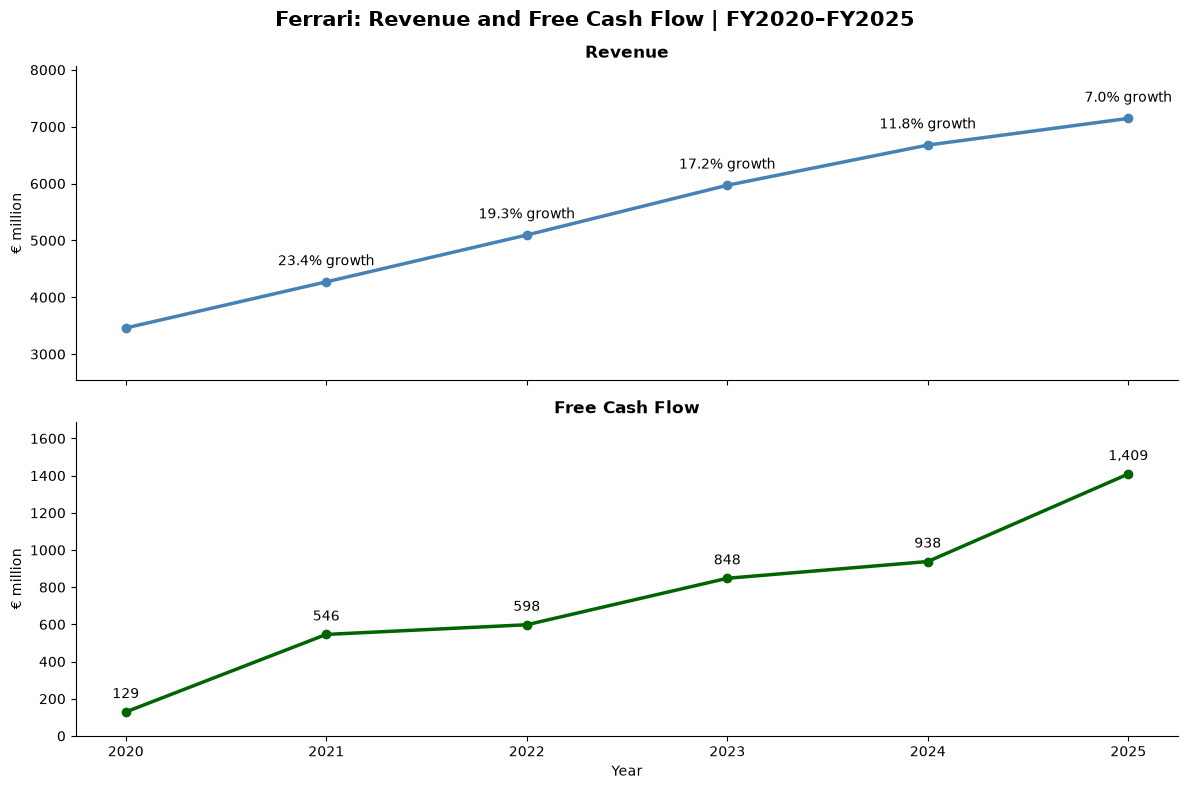

In [114]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(
    Ferrari_Operating_Inputs.index,
    Ferrari_Operating_Inputs['Revenue'],
    color='steelblue', marker='o', linewidth=2.5
)

for year, growth in Ferrari_Operating_Inputs['Revenue Growth'].dropna().items():
    axes[0].annotate(
        f'{growth:.1f}% growth',
        xy=(year, Ferrari_Operating_Inputs.loc[year, 'Revenue']),
        xytext=(0, 12), textcoords='offset points',
        ha='center', fontsize=10
    )

axes[0].set_title('Revenue', fontweight='bold')
axes[0].set_ylabel('€ million')
axes[0].margins(y=0.25)


axes[1].plot(
    Ferrari_Cashflow_Inputs.index,
    Ferrari_Cashflow_Inputs['Free Cash Flow'],
    color='darkgreen', marker='o', linewidth=2.5
)

for year, value in Ferrari_Cashflow_Inputs['Free Cash Flow'].items():
    axes[1].annotate(
        f'{value:,.0f}',
        xy=(year, value),
        xytext=(0, 10), textcoords='offset points',
        ha='center', fontsize=10
    )

axes[1].set_title('Free Cash Flow', fontweight='bold')
axes[1].set_ylabel('€ million')
axes[1].set_xlabel('Year')
axes[1].set_ylim(bottom=0)
axes[1].margins(y=0.20)
axes[1].set_xticks(Ferrari_Cashflow_Inputs.index)
axes[1].set_ylim(0, Ferrari_Cashflow_Inputs['Free Cash Flow'].max() * 1.20)

fig.patch.set_facecolor('white')

for ax in axes:
    ax.set_facecolor('white')
    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.suptitle(
    'Ferrari: Revenue and Free Cash Flow | FY2020–FY2025',
    fontsize=15, fontweight='bold'
)

plt.tight_layout()
plt.show()

In [115]:
fig.savefig('Ferrari_financial_visuals.png', dpi = 300, bbox_inches='tight')

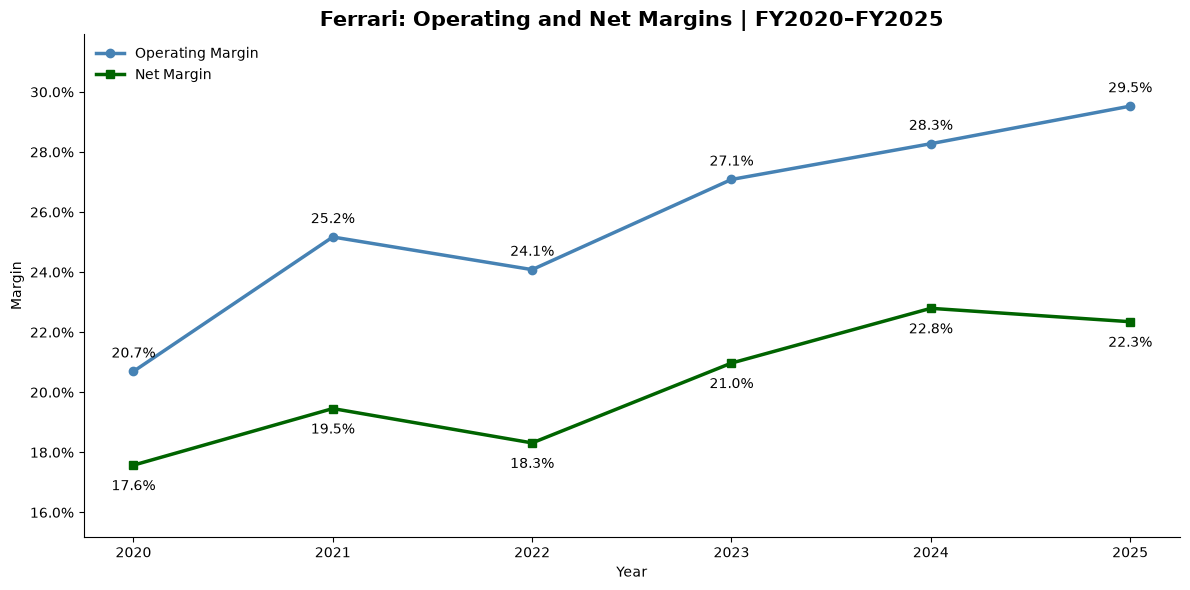

In [116]:
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(12, 6))

for column, color, marker, offset in [
    ('Operating Margin', 'steelblue', 'o', 10),
    ('Net Margin', 'darkgreen', 's', -18)
]:
    ax.plot(
        Ferrari_Operating_Inputs.index,
        Ferrari_Operating_Inputs[column],
        color=color, marker=marker,
        linewidth=2.5, label=column
    )

    for year, value in Ferrari_Operating_Inputs[column].items():
        ax.annotate(
            f'{value:.1f}%',
            xy=(year, value),
            xytext=(0, offset),
            textcoords='offset points',
            ha='center', fontsize=10
        )

ax.set_title(
    'Ferrari: Operating and Net Margins | FY2020–FY2025',
    fontsize=15, fontweight='bold'
)
ax.set_xlabel('Year')
ax.set_ylabel('Margin')
ax.set_xticks(Ferrari_Operating_Inputs.index)
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.margins(y=0.20)

fig.patch.set_facecolor('white')
ax.set_facecolor('white')
ax.grid(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

In [117]:
fig.savefig('Ferrari_margin_visuals.png', dpi=300, bbox_inches='tight')

# Historical vs YTD Performance 

In [118]:
Tickers = ('RACE', 'SPY')
HIST= pd.DataFrame()
for t in Tickers: 
    HIST[t]= yf.download(t, '2020-1-1','2026-1-1')['Close']

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [119]:
Tickers = ('RACE', 'SPY')
YTD = pd.DataFrame()
for t in Tickers:
    YTD[t]= yf.download(t, '2025-12-31','2026-10-10')['Close']

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [120]:
YTD.head()

,RACE,SPY
Date,,
2025-12-31,365.3435,676.6350
2026-01-02,367.6470,677.8753
2026-01-05,374.9427,682.3900
2026-01-06,367.7162,686.4484
2026-01-07,362.6249,684.2357


In [121]:
HIST.tail()

,RACE,SPY
Date,,
2025-12-24,372.0462,685.0295
2025-12-26,373.8158,684.9600
2025-12-29,371.4629,682.5190
2025-12-30,368.2302,681.6855
2025-12-31,365.3435,676.6350


In [122]:
HIST_SROR = HIST.pct_change()

In [123]:
HIST_SROR = HIST_SROR.dropna()

In [124]:
YTD_SROR = YTD.pct_change()

In [125]:
YTD_SROR = YTD_SROR.dropna()

In [126]:
MEAN_HIST_SROR = HIST_SROR.mean()

In [127]:
ANN_HIST = MEAN_HIST_SROR*252

In [128]:
YTD_RET = (YTD.iloc[-1]/YTD.iloc[0]-1)

In [129]:
HIST_STD = HIST_SROR.std()

In [130]:
HIST_VOL = HIST_STD*np.sqrt(252)

In [131]:
YTD_VOL = YTD_SROR.std()*np.sqrt(252)

In [132]:
HIST_PEAK = HIST.cummax()

In [133]:
HIST_Drawdown = (HIST - HIST_PEAK)/ HIST_PEAK

In [134]:
HIST_MAX = HIST_Drawdown.min()

In [135]:
YTD_PEAK = YTD.cummax()

In [136]:
YTD_Drawdown = (YTD - YTD_PEAK)/YTD_PEAK

In [137]:
YTD_MAX = YTD_Drawdown.min()

In [138]:
COV = HIST_SROR.cov()*252

In [139]:
VAR = HIST_SROR.var()*252

In [140]:
HBETA = COV['RACE'].iloc[1]/ VAR['SPY']

In [141]:
YCOV = YTD_SROR.cov()*252

In [142]:
YVAR = YTD_SROR.var()*252

In [143]:
YBETA = YCOV['RACE'].iloc[1]/YVAR['SPY']

In [144]:
RF_HIST = 0.0286

In [145]:
RF_YTD = 0.0380

In [146]:
Daily_RFH = ((1+RF_HIST)**(1/252))-1

In [147]:
Daily_RFY = ((1+RF_YTD)**(1/252))-1

In [148]:
H_DER = (HIST_SROR - Daily_RFH)

In [149]:
Y_DER = (YTD_SROR - Daily_RFY)

In [150]:
H_MDER = H_DER.mean()

In [151]:
H_SDER = H_DER.std()

In [152]:
HSharpe = (H_MDER/H_SDER)*np.sqrt(252)

In [153]:
Y_MDER = Y_DER.mean()

In [154]:
Y_SDER = Y_DER.std()

In [155]:
YSharpe = (Y_MDER / Y_SDER)*np.sqrt(252)

In [156]:
HDOWNSIDE = H_DER.clip(upper=0)

In [157]:
ANN_HDWN = np.sqrt((HDOWNSIDE ** 2).mean()) * np.sqrt(252)

In [158]:
YDOWNSIDE = Y_DER.clip(upper=0)

In [159]:
ANN_YDWN = np.sqrt((YDOWNSIDE ** 2).mean()) * np.sqrt(252)

In [160]:
HSortino = (H_MDER * 252)/ANN_HDWN

In [161]:
YSortino = (Y_MDER * 252)/ANN_YDWN 

In [225]:
Market_Return = H_MDER['SPY']*252

In [226]:
HCAPM = RF_HIST + HBETA*(Market_Return)

In [227]:
HCAPM

np.float64(0.15158462719778681)

In [228]:
Market_Return

np.float64(0.13200896831518322)

In [166]:
Arithmetic_Return = MEAN_HIST_SROR['RACE']*252

In [167]:
Arithmetic_Return

np.float64(0.18501997649625354)

In [229]:
YMarket_Return = Y_MDER['SPY']*252

In [230]:
YCAPM = RF_YTD + YBETA*(YMarket_Return)

In [231]:
YCAPM

np.float64(0.20125069042926946)

In [170]:
Cost_Of_Equity = GR_RF + HBETA*Market_ERP

In [171]:
WACC = (Equity_Weight*Cost_Of_Equity)+(Debt_Weight*Cost_Of_Debt)

In [172]:
ROIC_WACC_SPREAD = ROIC - (WACC*100)

In [173]:
YTD_SUMMARY = pd.DataFrame({
    'Metric': [
        'Actual Return', 'Annualized Volatility',
        'Sharpe', 'Sortino', 'Maximum Drawdown', 'Beta'
    ],
    'Ferrari': [
        YTD_RET['RACE'], YTD_VOL['RACE'],
        YSharpe['RACE'], YSortino['RACE'],
        YTD_MAX['RACE'], YBETA
    ],
    'SPY': [
        YTD_RET['SPY'], YTD_VOL['SPY'],
        YSharpe['SPY'], YSortino['SPY'],
        YTD_MAX['SPY'], 1.0
    ]
})

In [174]:
YTD_SUMMARY

,Metric,Ferrari,SPY
0,Actual Return,0.0672,0.1506
1,Annualized Volatility,0.3355,0.1301
2,Sharpe,0.3066,1.1796
3,Sortino,0.4672,1.7743
4,Maximum Drawdown,-0.1958,-0.0888
5,Beta,1.0638,1.0000


In [175]:
HIST_SUMMARY = pd.DataFrame({
    'Metric': [
        'Annualized Return', 'Annualized Volatility',
        'Sharpe', 'Sortino', 'Maximum Drawdown', 'Beta'
    ],
    'Ferrari': [
        ANN_HIST['RACE'], HIST_VOL['RACE'],
        HSharpe['RACE'], HSortino['RACE'],
        HIST_MAX['RACE'], HBETA
    ],
    'SPY': [
        ANN_HIST['SPY'], HIST_VOL['SPY'],
        HSharpe['SPY'], HSortino['SPY'],
        HIST_MAX['SPY'], 1.0
    ]
})

In [176]:
HIST_SUMMARY

,Metric,Ferrari,SPY
0,Annualized Return,0.1850,0.1602
1,Annualized Volatility,0.3058,0.2075
2,Sharpe,0.5128,0.6362
3,Sortino,0.7370,0.8940
4,Maximum Drawdown,-0.3829,-0.3372
5,Beta,0.9316,1.0000


In [177]:
RISK = YTD[['RACE']]

In [178]:
RISK['Return']= RISK.pct_change()

In [179]:
RISK = RISK.dropna(subset=['Return'])

In [180]:
VAR95 = RISK['Return'].quantile(0.05)

In [181]:
tail_losses_95 = RISK.loc[
    RISK['Return'] <= VAR95,
    'Return'
]

In [182]:
CVAR = tail_losses_95.mean()

In [183]:
VAR_95 = -VAR95

In [184]:
CVAR= -CVAR

In [185]:
Return = RISK['Return']

In [186]:
VAR_LINE = -abs(VAR95)
CVAR_LINE = -abs(CVAR)

In [187]:
import seaborn as sns

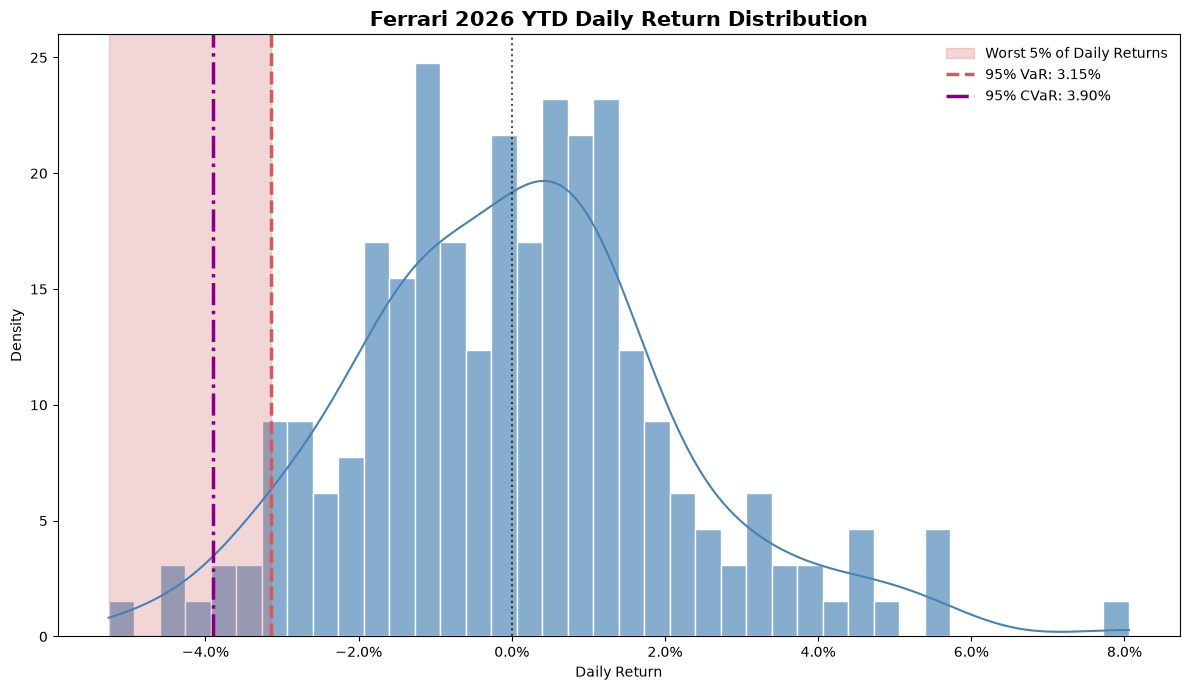

In [188]:
fig, ax = plt.subplots(figsize=(12, 7))

sns.histplot(
    Return,
    bins=40,
    kde=True,
    stat="density",
    color="steelblue",
    alpha=0.65,
    edgecolor="white",
    ax=ax
)

ax.axvspan(
    Return.min(),
    VAR_LINE,
    color="indianred",
    alpha=0.25,
    label="Worst 5% of Daily Returns"
)

ax.axvline(
    VAR_LINE,
    color="indianred",
    linestyle="--",
    linewidth=2.5,
    label=f"95% VaR: {abs(VAR95):.2%}"
)

ax.axvline(
    CVAR_LINE,
    color="purple",
    linestyle="-.",
    linewidth=2.5,
    label=f"95% CVaR: {abs(CVAR):.2%}"
)

ax.axvline(
    0,
    color="black",
    linestyle=":",
    linewidth=1.5,
    alpha=0.7
)

ax.set_title(
    "Ferrari 2026 YTD Daily Return Distribution",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Daily Return")
ax.set_ylabel("Density")

ax.xaxis.set_major_formatter(PercentFormatter(1))

ax.grid(alpha=0.15)
ax.legend(frameon=False)
ax.grid(False)

plt.tight_layout()
plt.show()

In [189]:
fig.savefig('Ferrai_var_cvar.png', dpi = 300, bbox_inches='tight')

In [190]:
Normalized = HIST[['RACE','SPY']]/HIST[['RACE','SPY']].iloc[0]*100

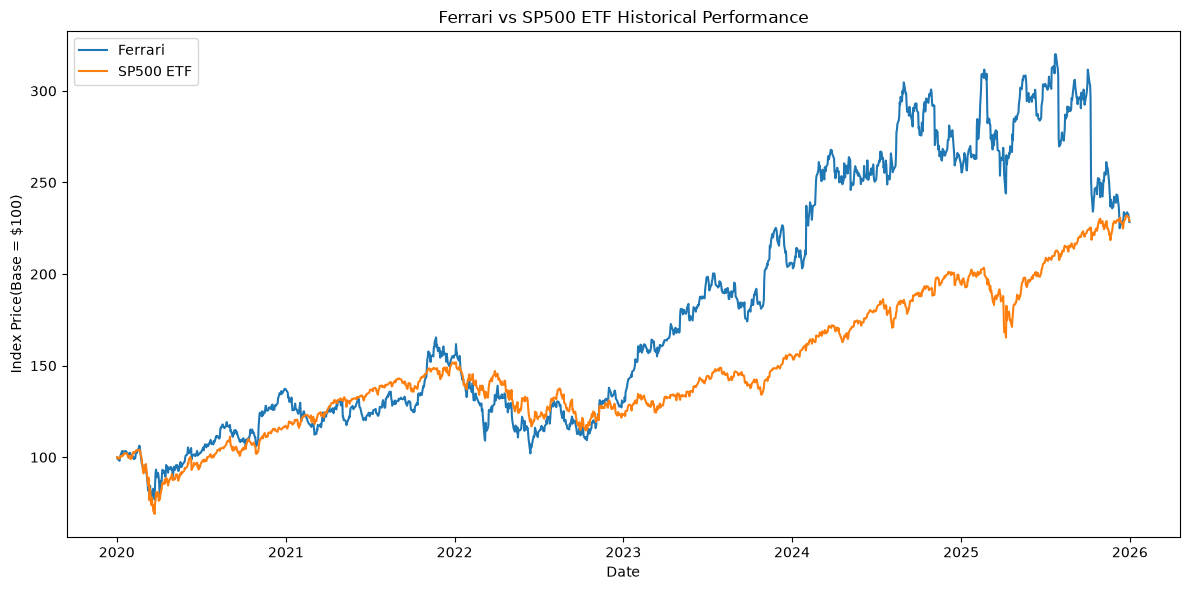

In [191]:
fig, ax = plt.subplots(figsize=(12,6))

ax.plot(Normalized.index, 
       Normalized['RACE'],
       label ='Ferrari')
ax.plot(Normalized.index,
       Normalized['SPY'],
       label = 'SP500 ETF')

ax.set_title('Ferrari vs SP500 ETF Historical Performance')
ax.set_xlabel('Date')
ax.set_ylabel('Index Price(Base = $100)')
ax.legend()

fig.tight_layout()

plt.show()

In [192]:
fig.savefig('Ferrari_historical.png', dpi=300, bbox_inches='tight')

In [193]:
Normalized1 = YTD[['RACE','SPY']]/YTD[['RACE','SPY']].iloc[0]*100

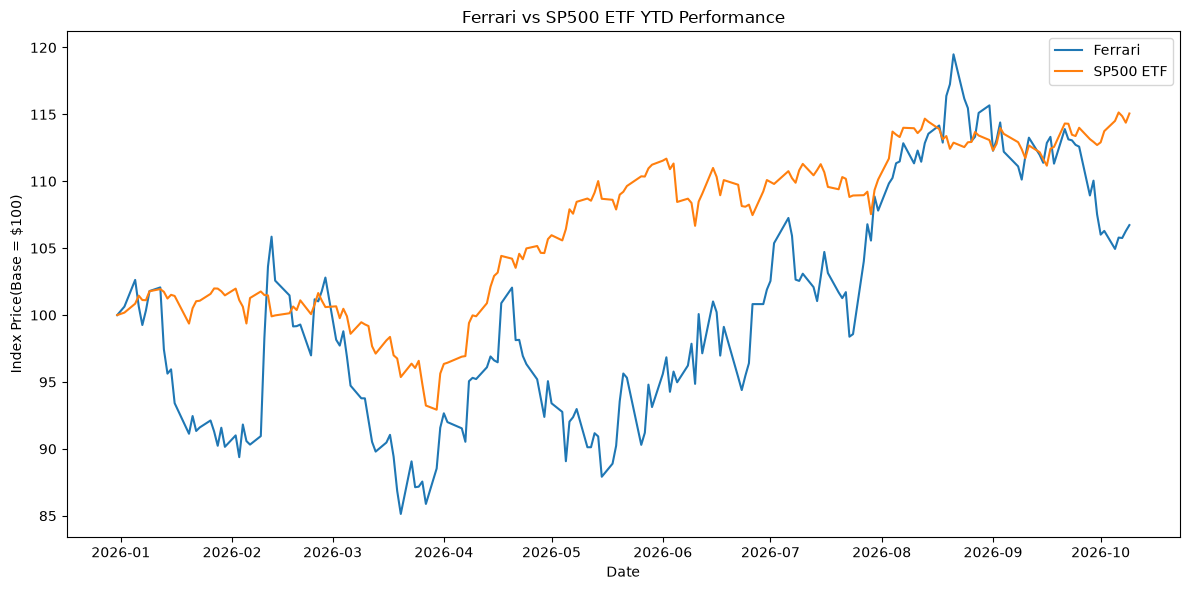

In [194]:
fig, ax = plt.subplots(figsize=(12,6))

ax.plot(Normalized1.index, 
       Normalized1['RACE'],
       label ='Ferrari')
ax.plot(Normalized1.index,
       Normalized1['SPY'],
       label = 'SP500 ETF')

ax.set_title('Ferrari vs SP500 ETF YTD Performance')
ax.set_xlabel('Date')
ax.set_ylabel('Index Price(Base = $100)')
ax.legend()

fig.tight_layout()

plt.show()

In [195]:
fig.savefig('Ferrari_YTD_performance.png', dpi=300, bbox_inches='tight')

In [196]:
HRatio = pd.DataFrame({
    "Sharpe": HSharpe,
    "Sortino": HSortino
})

In [197]:
YRatio = pd.DataFrame({
    "Sharpe": YSharpe,
    "Sortino": YSortino
})

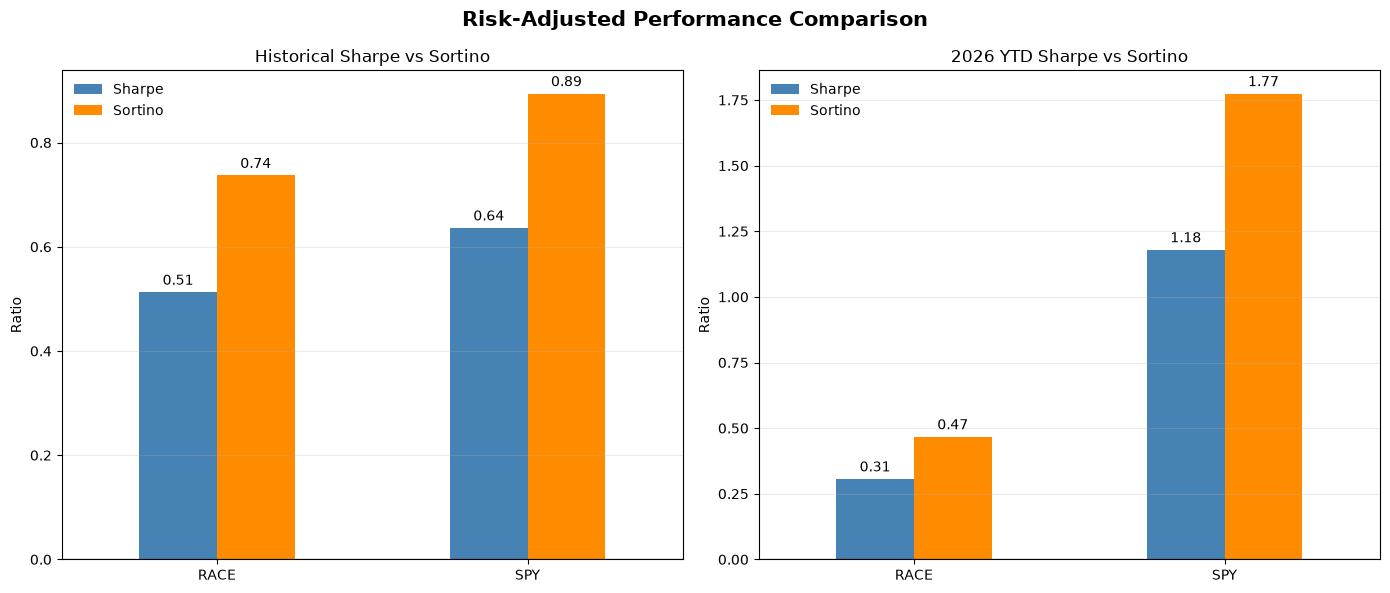

In [198]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6)
)

HRatio.plot(
    kind="bar",
    ax=axes[0],
    color=["steelblue", "darkorange"]
)

YRatio.plot(
    kind="bar",
    ax=axes[1],
    color=["steelblue", "darkorange"]
)

axes[0].set_title("Historical Sharpe vs Sortino")
axes[1].set_title("2026 YTD Sharpe vs Sortino")

for ax in axes:

    ax.set_xlabel("")
    ax.set_ylabel("Ratio")
    ax.tick_params(axis="x", rotation=0)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False)

    for bars in ax.containers:
        ax.bar_label(
            bars,
            fmt="%.2f",
            padding=3
        )

fig.suptitle(
    "Risk-Adjusted Performance Comparison",
    fontsize=15,
    fontweight="bold"
)

fig.tight_layout()
plt.show()

In [199]:
fig.savefig('Ferrari_risk_adjusted.png', dpi=300, bbox_inches='tight')

In [200]:
TECH = yf.download('RACE', '2024-10-01', '2026-10-10')

[*********************100%***********************]  1 of 1 completed


In [201]:
TECH.head()

Price,Close,High,Low,Open,Volume
Ticker,RACE,RACE,RACE,RACE,RACE
Date,,,,,
2024-10-01,447.0952,457.3541,446.0261,456.7460,323300
2024-10-02,448.3702,450.9594,447.1638,450.4788,287200
2024-10-03,441.4361,443.6036,437.7190,441.9658,324000
2024-10-04,441.1615,442.2305,438.1996,439.6217,289700
2024-10-07,440.8869,442.6228,438.0132,441.0830,366300


In [202]:
TECH= TECH[['Open','High','Low','Close','Volume']]

In [203]:
TECH['50MA']= TECH['Close'].rolling(window = 50).mean()

In [204]:
TECH['100MA']= TECH['Close'].rolling(window = 100).mean()

In [205]:
TECH['200MA']=TECH['Close'].rolling(window = 200).mean()

In [206]:
TECH.head()

Price,Open,High,Low,Close,Volume,50MA,100MA,200MA
Ticker,RACE,RACE,RACE,RACE,RACE,,,
Date,,,,,,,,
2024-10-01,456.7460,457.3541,446.0261,447.0952,323300,NaN,NaN,NaN
2024-10-02,450.4788,450.9594,447.1638,448.3702,287200,NaN,NaN,NaN
2024-10-03,441.9658,443.6036,437.7190,441.4361,324000,NaN,NaN,NaN
2024-10-04,439.6217,442.2305,438.1996,441.1615,289700,NaN,NaN,NaN
2024-10-07,441.0830,442.6228,438.0132,440.8869,366300,NaN,NaN,NaN


In [207]:
TECH.columns = TECH.columns.get_level_values(0)
TECH.columns.name = None

In [208]:
sma50 = mpf.make_addplot(TECH['50MA'], color='blue',width=0.8)
sma100 = mpf.make_addplot(TECH['100MA'], color='orange',width=1.5)
sma200 = mpf.make_addplot(TECH['200MA'],color='purple', width=1.5)

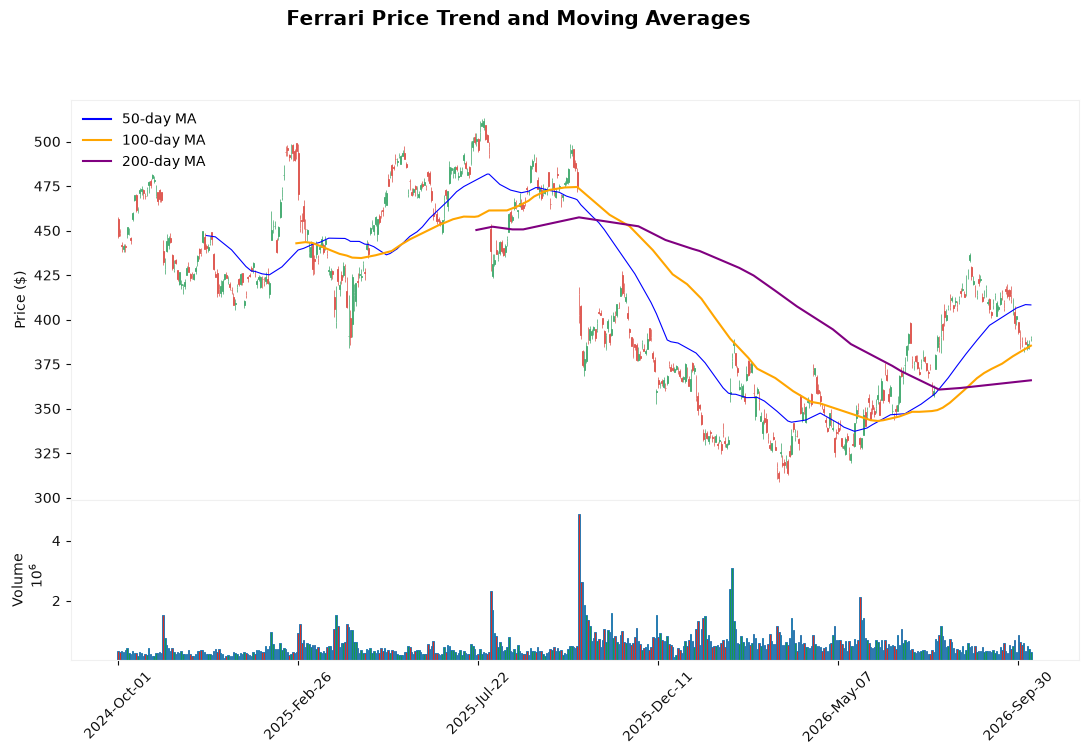

In [233]:
from matplotlib.lines import Line2D

mc1 = mpf.make_marketcolors(
    up="#1a9850",
    down="#d73027",
    edge="inherit",
    wick="inherit",
    volume="inherit"
)


style1 = mpf.make_mpf_style(
    base_mpf_style="yahoo",
    marketcolors=mc1,
    gridstyle="--",
    gridcolor="#dddddd",
    facecolor="white",
    figcolor="white",
    y_on_right=False,
    rc={"font.size": 10}
)

fig, axes = mpf.plot(
    TECH,
    type="candle",
    style=style1,
    addplot=[sma50, sma100, sma200],
    volume=True,
    figsize=(14, 8),
    title="Ferrari Price Trend and Moving Averages",
    ylabel="Price ($)",
    ylabel_lower="Volume",
    returnfig=True
)

for ax in axes:
    ax.grid(False)

axes[0].legend(
    handles=[
        Line2D([0], [0], color='blue', label='50-day MA'),
        Line2D([0], [0], color='orange', label='100-day MA'),
        Line2D([0], [0], color='purple', label='200-day MA')
    ],
    loc='upper left',
    frameon=False
)
plt.show()

In [234]:
fig.savefig('Ferrari_technicals.png', dpi=300, bbox_inches='tight')

# Comparative Valuation 

In [211]:
Ferrari_Implied_Enterprise_Value = TTM_EBITDA * Estimated_Porsche_EV_EBITDA

In [212]:
Ferrari_Implied_Enterprise_Value

np.float64(26994781989.50682)

In [213]:
Ferrari_Implied_Equity_Value = Ferrari_Implied_Enterprise_Value - Balance_Input.loc[0, 'Converted']+ Balance_Input.loc[1, 'Converted']-Balance_Input.loc[2, 'Converted']

In [214]:
Ferrari_Implied_Equity_Value 

np.float64(25308659989.50682)

In [215]:
Ferrari_Implied_Share_Price = Ferrari_Implied_Equity_Value / Shares_Outstanding

In [216]:
Ferrari_Implied_Share_Price

np.float64(144.29113395328037)

In [217]:
Implied_Upside_Downside = (Ferrari_Implied_Share_Price / Price_EUR - 1)*100

In [218]:
Implied_Upside_Downside

np.float64(-58.53077769022441)

In [219]:
COMPARATIVE = pd.DataFrame({
        'Metric': ['Value'],
        'Porsche EV/EBITDA Multiple': [Estimated_Porsche_EV_EBITDA],
        'Ferrari Implied Enterprise Value': [Ferrari_Implied_Enterprise_Value/1_000_000],
        'Ferrari Implied Equity Value': [Ferrari_Implied_Equity_Value/1_000_000],
        'Implied Price Per Share': [Ferrari_Implied_Share_Price],
        'Current Price Per Share': [Price_EUR],
        'Implied Upside/Downside': [Implied_Upside_Downside]
})
COMPARATIVE.style.format({'Value': '{:,.2f}'}).hide(axis='index')

Metric,Porsche EV/EBITDA Multiple,Ferrari Implied Enterprise Value,Ferrari Implied Equity Value,Implied Price Per Share,Current Price Per Share,Implied Upside/Downside
Value,9.481834,26994.781990,25308.659990,144.291134,347.947528,-58.530778


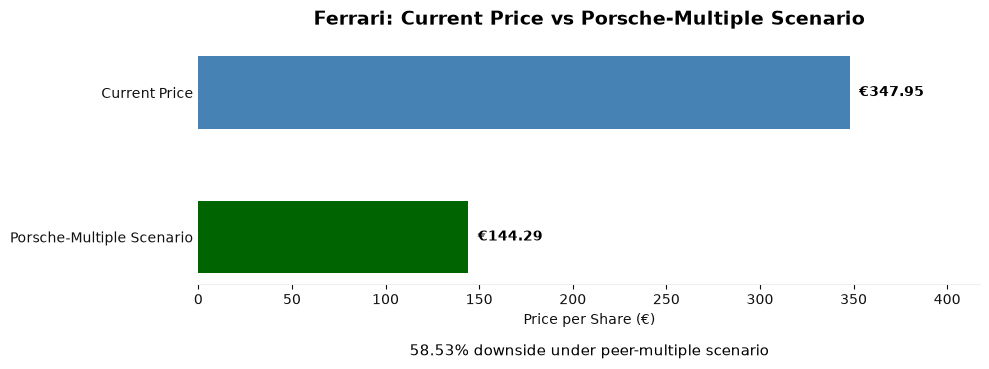

In [220]:
fig, ax = plt.subplots(figsize=(10, 4))

labels = ['Current Price', 'Porsche-Multiple Scenario']
prices = [Price_EUR, Ferrari_Implied_Share_Price]

ax.barh(labels, prices, color=['steelblue', 'darkgreen'], height=0.5)

for position, price in enumerate(prices):
    ax.text(price + 5, position, f'€{price:,.2f}',
            va='center', fontweight='bold')

ax.invert_yaxis()
ax.set_xlim(0, max(prices) * 1.20)
ax.set_xlabel('Price per Share (€)')
ax.set_title('Ferrari: Current Price vs Porsche-Multiple Scenario',
             fontsize=14, fontweight='bold', pad=15)

ax.text(
    0.5, -0.30,
    f'{abs(Implied_Upside_Downside):.2f}% downside under peer-multiple scenario',
    transform=ax.transAxes, ha='center', fontsize=11
)

fig.patch.set_facecolor('white')
ax.set_facecolor('white')
ax.grid(False)
ax.tick_params(axis='y', length=0)

for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

In [221]:
fig.savefig('Ferrari_comparative_multiple.png', dpi=300, bbox_inches='tight')

Ferrari trades at an EV/EBITDA premium to Porsche; matching Porsche’s multiple implies 58.53% downside.